# Hindi Speech Age Classification — Mozilla Common Voice (`cv-corpus-26.0`, `hi`)

**4-class, strictly speaker-independent** age classification (`teens`, `twenties`, `thirties`, `fourties`), comparing:

- OpenSMILE **62**-feature set
- OpenSMILE **88**-feature set
- **180**-dimensional combined representation (40 MFCC + 128 Mel + 12 Chroma, mean-pooled over time)
- A **2D CNN** trained directly on Mel-spectrogram images

This is a corrected revision of an earlier version of this notebook. Section 2 documents exactly what was wrong before, what was verified against official documentation, and what is stated as an explicit assumption because no course tutorial was supplied.


## 2. Methodology decisions and assumptions — read this first

This section exists so that every non-obvious methodological choice is explicit, sourced, and auditable, rather than silently baked into code.

### 2.1 What was corrected from the previous version

| Issue in previous notebook | Correction made here |
|---|---|
| Speaker split used two chained `GroupShuffleSplit` calls (random, non-stratified) | Replaced with **`sklearn.model_selection.StratifiedGroupKFold`** (7 folds; 5→train, 1→val, 1→test), which preserves class proportions per split while keeping groups (`client_id`) fully non-overlapping — verified against the official scikit-learn docs (Section 2.3). |
| No check for speakers with inconsistent age labels | Added: any `client_id` with more than one distinct reported `age` value is detected, reported, and **excluded** rather than arbitrarily resolved. |
| Final ML models were evaluated on test using a scaler fit on train-only, with hyperparameters chosen on the same train/val split used for the final fit | Corrected to the standard nested procedure: **tune** on train→val (scaler fit on train only), then **refit the final model and its scaler on train+validation combined** with the chosen hyperparameters, then evaluate **once** on test. |
| Arbitrary hard truncation of every clip to a fixed max duration, framed as a methodological choice | No tutorial specifies this, so clips are **not** truncated for any experiment by default; a very generous safety cap exists purely as a memory guard and is documented as such, not as methodology. |
| OpenSMILE feature-set choice for "88 features" was `eGeMAPSv02` without checking alternatives | Verified at the official `opensmile-python` GitHub README: **both `eGeMAPSv01b` and `eGeMAPSv02`, at the `Functionals` level, produce 88 features** (v2.0.0+ of the package). Per this assignment's own suggested default, `eGeMAPSv01b` is used; `eGeMAPSv02` remains available as a one-line swap (Section 13). |
| CNN image normalization used ImageNet mean/std | Corrected to compute mean/std **from the training Mel images only** (Section 20), since Mel-spectrogram images are not natural photographs and ImageNet statistics are not a principled default here. |
| `NUM_WORKERS` defaulted to 2, `torch.cuda.amp` (deprecated) used for AMP | `NUM_WORKERS = 0` by default (Windows/Jupyter-safe); AMP uses the current `torch.amp.autocast("cuda", ...)` / `torch.amp.GradScaler("cuda", ...)` API, enabled only when CUDA is available. |
| No explicit assumptions section | This section. |

### 2.2 Assumptions made because no course tutorial file was provided

No tutorial/course material was uploaded alongside this assignment brief. Where the brief itself did not fully pin down a method, the following **explicit, stated** defaults are used. If your course tutorial specifies something different, change only the flagged configuration variables (Sections 5, 13, 14, 16) — the rest of the notebook is agnostic to these choices as long as the resulting dimensionality is correct.

1. **OpenSMILE "62 features"** = `opensmile.FeatureSet.GeMAPSv01b` at `opensmile.FeatureLevel.Functionals`. Verified to output exactly 62 features for `opensmile` package version ≥ 2.0.0 (see the official `audeering/opensmile-python` README feature-count table).
2. **OpenSMILE "88 features"** = `opensmile.FeatureSet.eGeMAPSv01b` at `opensmile.FeatureLevel.Functionals`, as the notebook's explicit default assumption because no course tutorial was provided here. Verified to output exactly 88 features for `opensmile` ≥ 2.0.0. (`eGeMAPSv02` also yields 88; if the course tutorial specifies it, use that exact version.)
3. **180-dimensional feature representation** = 40 MFCC + 128 Mel-band energies (dB) + 12 Chroma, each **mean-pooled over time** to a fixed-length vector, then concatenated. This is called the **"180-dimensional combined feature representation"** throughout — not "selected features" — because no feature-selection algorithm (e.g. mutual information, RFE) is applied; all 180 dimensions are kept.
4. **Speaker-independent split ratios** ≈ 70/15/15 are targeted via `StratifiedGroupKFold(n_splits=7)`, with 5 folds assigned to train, 1 to validation, and 1 to test. The val/test fold pair is chosen **deterministically** (Section 10) to (a) keep every fold's class distribution close to the overall dataset's class distribution and (b) guarantee all 4 classes are present in every split — not by an arbitrary/random fold pick.
5. **Audio is not truncated** as a matter of methodology (nothing in the brief calls for it); no duration cap is applied by default; `MAX_DURATION_SEC` is available only as an explicit user-selected safety setting and is not part of the reported methodology.
6. **CNN normalization statistics** are computed from the training Mel images themselves (Section 20), not borrowed from ImageNet.

### 2.3 What was verified against authoritative sources (not assumed)

- **OpenSMILE feature counts.** Confirmed directly from the official `audeering/opensmile-python` GitHub README's feature-count table (package v2.0.0+): `GeMAPSv01b` Functionals → 62; `eGeMAPSv01a` / `eGeMAPSv01b` / `eGeMAPSv02` Functionals → 88 each.
- **`StratifiedGroupKFold` semantics.** Confirmed from the official scikit-learn documentation: it is *"a variation of `StratifiedKFold` that attempts to return stratified folds with non-overlapping groups... each group will appear exactly once in the test set across all folds."* This is exactly the property required here: no `client_id` ever appears in more than one fold, and within that hard constraint, class proportions are preserved as well as possible.
- **`opensmile.Smile.process_signal(signal, sampling_rate)`.** Confirmed from the official `opensmile-python` usage examples (audEERING blog / README): the Python wrapper accepts a raw waveform array plus its sampling rate directly, which this notebook uses to guarantee OpenSMILE always receives the *same* 16 kHz mono signal already used for every other feature set (rather than re-decoding the file internally at a possibly different rate).


## 3. Assignment objective

Perform 4-class age classification (`teens`, `twenties`, `thirties`, `fourties`) on Common Voice Hindi speech, comparing three classical-ML feature representations (OpenSMILE-62, OpenSMILE-88, 180-dim MFCC+Mel+Chroma) against a 2D CNN trained on Mel-spectrogram images, under a strict speaker-independent train/validation/test split shared across every experiment. Whether the CNN achieves the best performance is determined empirically in Section 24 — it is not assumed in advance.


In [3]:
# ============================================================
# 4. IMPORTS
# ============================================================
import os, sys, json, time, random, warnings, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

# Optional / heavy deps are imported defensively so the notebook degrades gracefully
try:
    import librosa
    import librosa.display
    HAVE_LIBROSA = True
except ImportError:
    HAVE_LIBROSA = False
    print("librosa not installed -> run: pip install librosa")

try:
    import opensmile
    HAVE_OPENSMILE = True
except ImportError:
    HAVE_OPENSMILE = False
    print("opensmile not installed -> run: pip install opensmile")

try:
    import xgboost as xgb
    HAVE_XGBOOST = True
except ImportError:
    HAVE_XGBOOST = False
    print("xgboost not installed -> falling back to HistGradientBoostingClassifier (reported explicitly wherever used)")

try:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader
    HAVE_TORCH = True
except ImportError:
    HAVE_TORCH = False
    print("torch not installed -> run: pip install torch torchvision")

from tqdm.auto import tqdm

print("Imports complete.")


Imports complete.


In [4]:
# ============================================================
# 5. CONFIGURATION  -- EDIT THIS CELL FOR YOUR MACHINE / COURSE
# ============================================================

# --- Dataset location -----------------------------------------------------
# Point this at the extracted Common Voice "hi" folder (the one that directly
# contains train.tsv / dev.tsv / test.tsv / validated.tsv / clips/).
DATASET_ROOT = r"1781715680033-cv-corpus-26.0-2026-06-12-hi/cv-corpus-26.0-2026-06-12/hi"

# If DATASET_ROOT does not resolve automatically, set this manually, e.g.
# MANUAL_TSV_DIR = r"C:\Users\me\Downloads\cv-corpus-26.0-2026-06-12\hi"
MANUAL_TSV_DIR = None

# --- Project folders --------------------------------------------------------
PROJECT_ROOT   = Path("project")
DATASET_DIR    = PROJECT_ROOT / "dataset"
FEATURES_DIR   = PROJECT_ROOT / "features"
MEL_IMAGES_DIR = PROJECT_ROOT / "mel_images"
SPLITS_DIR     = PROJECT_ROOT / "splits"
MODELS_DIR     = PROJECT_ROOT / "models"
RESULTS_DIR    = PROJECT_ROOT / "results"

for d in [PROJECT_ROOT, DATASET_DIR, FEATURES_DIR, MEL_IMAGES_DIR,
          MEL_IMAGES_DIR / "train", MEL_IMAGES_DIR / "val", MEL_IMAGES_DIR / "test",
          SPLITS_DIR, MODELS_DIR, RESULTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# --- Class definition -------------------------------------------------------
AGE_CLASSES = ["teens", "twenties", "thirties", "fourties"]

# --- Audio preprocessing -----------------------------------------------------
SR = 16000                     # reference sample rate used EVERYWHERE (Section 2.2 item 6 / 2.3)
# Memory-safety cap only (NOT a methodological truncation -- see Section 2.2 item 5).
# Set to None to disable entirely (uses full clip length; Common Voice clips are short,
# typically well under this by construction).
MAX_DURATION_SEC = None

# --- 180-dim feature config (Section 2.2 item 3) ------------------------------
N_MFCC   = 40
N_MELS   = 128
N_CHROMA = 12
N_FFT_FEAT = 2048
HOP_LENGTH_FEAT = 512
FEATURE_180_VERSION = "v2-meanpool-fullclip"   # bump this if the aggregation method ever changes

# --- Mel-spectrogram image config (for CNN) ----------------------------------
N_MELS_IMG     = 128
N_FFT_IMG      = 1024
HOP_LENGTH_IMG = 512
IMAGE_SIZE     = 224
MEL_IMAGE_VERSION = "v2-nomargin-nocbar-fullclip"   # bump this if rendering ever changes -> avoids stale-cache reuse

# --- OpenSMILE config (Section 2.2 items 1-2; change here if your tutorial differs) ---
OPENSMILE_62_FEATURE_SET  = "GeMAPSv01b"   # -> opensmile.FeatureSet.GeMAPSv01b
OPENSMILE_88_FEATURE_SET  = "eGeMAPSv01b"  # -> opensmile.FeatureSet.eGeMAPSv01b  (eGeMAPSv02 also valid, see Sec. 13)
OPENSMILE_FEATURE_LEVEL   = "Functionals"

# --- Speaker-independent split (Section 10) -----------------------------------
N_SPLIT_FOLDS = 7          # 5 folds -> train (~71%), 1 -> val (~14%), 1 -> test (~14%)
SPLIT_SEED = 42
SPLIT_VERSION = "v2-stratifiedgroupkfold7"   # bump if the split *method* ever changes

# --- Hardware / training config ------------------------------------------------
BATCH_SIZE   = 32
NUM_WORKERS  = 0            # 0 by default: safest in Jupyter/Windows (avoids multiprocessing issues)
CNN_EPOCHS   = 30
CNN_PATIENCE = 6            # early-stopping patience, monitored on validation Macro F1
LR = 1e-3
USE_AMP = True              # only actually engages if CUDA is available

# --- Reproducibility ----------------------------------------------------------
GLOBAL_SEED = 42

# --- Dev-mode safety valve -----------------------------------------------------
# Smoke-test the whole pipeline on a small subset before a full run. None = full dataset.
MAX_CLIPS_PER_CLASS = None

print("Configuration loaded. Project root:", PROJECT_ROOT.resolve())


Configuration loaded. Project root: E:\sem 7\Speech Processing\assign 3\project


## 6. Environment, versions, reproducibility

Seed every RNG and print every tool's version so results are attributable to a specific software configuration, per the assignment's reproducibility requirement.

In [5]:
# ============================================================
# 6. ENVIRONMENT / VERSIONS / REPRODUCIBILITY
# ============================================================
def set_all_seeds(seed=GLOBAL_SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if HAVE_TORCH:
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_all_seeds(GLOBAL_SEED)

import sklearn
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("librosa:", librosa.__version__ if HAVE_LIBROSA else "NOT INSTALLED")
print("opensmile:", opensmile.__version__ if HAVE_OPENSMILE else "NOT INSTALLED")
print("xgboost:", xgb.__version__ if HAVE_XGBOOST else "NOT INSTALLED (fallback: HistGradientBoostingClassifier)")

if HAVE_TORCH:
    print("torch:", torch.__version__)
    CUDA_AVAILABLE = torch.cuda.is_available()
    print("CUDA available:", CUDA_AVAILABLE)
    if CUDA_AVAILABLE:
        print("GPU:", torch.cuda.get_device_name(0))
    DEVICE = torch.device("cuda" if CUDA_AVAILABLE else "cpu")
else:
    CUDA_AVAILABLE = False
    DEVICE = None
print("Device selected for CNN:", DEVICE)


Python: 3.11.9
NumPy: 2.4.6
pandas: 3.0.6
scikit-learn: 1.9.1
librosa: 0.11.0
opensmile: 2.6.0
xgboost: 3.2.0
torch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Device selected for CNN: cuda


## 7. Dataset discovery

Locates `train.tsv`, `dev.tsv`, `test.tsv`, `validated.tsv` under `DATASET_ROOT` (or `MANUAL_TSV_DIR`), searching a few levels deep since extraction layouts vary.

In [6]:
# ============================================================
# 7. DATASET DISCOVERY
# ============================================================
REQUIRED_TSVS = ["train.tsv", "dev.tsv", "test.tsv", "validated.tsv"]

def find_tsv_dir(root, required=REQUIRED_TSVS):
    root = Path(root)
    if not root.exists():
        return None
    candidates = [root] + [p for p in root.rglob("*") if p.is_dir()]
    for cand in candidates:
        if all((cand / f).exists() for f in required):
            return cand
    return None

tsv_dir = None
if MANUAL_TSV_DIR is not None:
    tsv_dir = Path(MANUAL_TSV_DIR)
    assert all((tsv_dir / f).exists() for f in REQUIRED_TSVS), \
        f"MANUAL_TSV_DIR is set but is missing one of {REQUIRED_TSVS}"
else:
    tsv_dir = find_tsv_dir(DATASET_ROOT)
    if tsv_dir is None:
        for alt in [Path(DATASET_ROOT), Path(DATASET_ROOT).parent, Path(".")]:
            tsv_dir = find_tsv_dir(alt)
            if tsv_dir is not None:
                break

if tsv_dir is None:
    raise FileNotFoundError(
        "Could not locate train/dev/test/validated.tsv automatically.\n"
        "Set MANUAL_TSV_DIR in the Configuration cell (Section 5) to the folder "
        "that directly contains these files, then re-run from Section 7."
    )

clips_dir = tsv_dir / "clips"
print("Resolved TSV directory:", tsv_dir.resolve())
print("Resolved clips directory:", clips_dir.resolve(), "| exists:", clips_dir.exists())
for f in REQUIRED_TSVS:
    print(f"  {f}: found")


Resolved TSV directory: E:\sem 7\Speech Processing\assign 3\1781715680033-cv-corpus-26.0-2026-06-12-hi\cv-corpus-26.0-2026-06-12\hi
Resolved clips directory: E:\sem 7\Speech Processing\assign 3\1781715680033-cv-corpus-26.0-2026-06-12-hi\cv-corpus-26.0-2026-06-12\hi\clips | exists: True
  train.tsv: found
  dev.tsv: found
  test.tsv: found
  validated.tsv: found


## 8. Dataset loading and filtering

We use `validated.tsv` as the base pool, since it is the superset of community-validated clips and already includes the rows also present in the official `train`/`dev`/`test` splits. We deliberately **do not** use Common Voice's own `train`/`dev`/`test` split — it is not guaranteed to be speaker-independent for our four target classes, and this assignment requires us to build our own (Section 10).

All counts below are computed from the actual downloaded files, not assumed from any datasheet.


In [ ]:
# ============================================================
#  DATASET LOADING AND FILTERING
# ============================================================
AGE_CLASSES = ["teens", "twenties", "thirties", "fourties"]
def load_tsv(path):
    return pd.read_csv(path, sep="\t", low_memory=False)

validated_df = load_tsv(tsv_dir / "validated.tsv")
print("validated.tsv (base pool):", validated_df.shape)
print("Columns:", list(validated_df.columns))

n_before = len(validated_df)

df = validated_df.copy()
df["age"] = df["age"].astype(str).str.strip().str.lower()

# 1) keep only the 4 required classes
df = df[df["age"].isin(AGE_CLASSES)].copy()
n_after_age_filter = len(df)
# 2) drop rows missing essential fields
df = df.dropna(subset=["path", "client_id", "age"]).copy()
# 3) drop rows whose audio file does not actually exist on disk
df["abs_path"] = df["path"].apply(lambda p: str(clips_dir / p))
exists_mask = df["abs_path"].apply(os.path.exists)
n_missing_files = int((~exists_mask).sum())
df = df[exists_mask].copy()

# 4) drop exact duplicate clip entries
df = df.drop_duplicates(subset=["path"]).copy()

# 5) exclude speakers with inconsistent age labels (Section 2.1 correction)
age_per_speaker = df.groupby("client_id")["age"].nunique()
inconsistent_speakers = age_per_speaker[age_per_speaker > 1].index.tolist()
if inconsistent_speakers:
    inconsistent_rows = df[df["client_id"].isin(inconsistent_speakers)]
    inconsistent_rows.to_csv(RESULTS_DIR / "excluded_inconsistent_age_speakers.csv", index=False)
    print(f"⚠ {len(inconsistent_speakers)} speaker(s) have inconsistent age labels across clips -- "
          f"excluded ({len(inconsistent_rows)} clips). Logged to "
          f"{RESULTS_DIR / 'excluded_inconsistent_age_speakers.csv'}")
    df = df[~df["client_id"].isin(inconsistent_speakers)].copy()
else:
    print("No speakers with inconsistent age labels found.")

n_after = len(df)

print(f"\nRecords before filtering (validated.tsv): {n_before}")
print(f"Records after age-class filtering to {AGE_CLASSES}: {n_after_age_filter}")
print(f"Rows dropped for missing audio file on disk: {n_missing_files}")
print(f"Records after all filtering (existing audio, deduped, consistent-age speakers): {n_after}")

print("\nActual class counts (computed from data, not assumed from any datasheet):")
print(df["age"].value_counts().reindex(AGE_CLASSES))

if MAX_CLIPS_PER_CLASS is not None:
    print(f"\n[DEV MODE] Subsampling to at most {MAX_CLIPS_PER_CLASS} clips/class for a fast smoke test.")
    df = (df.groupby("age", group_keys=False)
            .apply(lambda g: g.sample(min(len(g), MAX_CLIPS_PER_CLASS), random_state=GLOBAL_SEED)))
    print("Post-subsample counts:\n", df["age"].value_counts().reindex(AGE_CLASSES))

df = df.reset_index(drop=True)
df["clip_id"] = df["path"].apply(lambda p: Path(p).stem)
df.to_csv(FEATURES_DIR / "filtered_pool.csv", index=False)
print("\nSaved filtered pool ->", FEATURES_DIR / "filtered_pool.csv")
df.head()


validated.tsv (base pool): (11131, 13)
Columns: ['client_id', 'path', 'sentence_id', 'sentence', 'sentence_domain', 'up_votes', 'down_votes', 'age', 'gender', 'accents', 'variant', 'locale', 'segment']
⚠ 1 speaker(s) have inconsistent age labels across clips -- excluded (3 clips). Logged to project\results\excluded_inconsistent_age_speakers.csv

Records before filtering (validated.tsv): 11131
Records after age-class filtering to ['teens', 'twenties', 'thirties', 'fourties']: 7429
Rows dropped for missing audio file on disk: 0
Records after all filtering (existing audio, deduped, consistent-age speakers): 7426

Actual class counts (computed from data, not assumed from any datasheet):
age
teens        132
twenties    4098
thirties    2914
fourties     282
Name: count, dtype: int64

Saved filtered pool -> project\features\filtered_pool.csv


,client_id,path,sentence_id,sentence,sentence_domain,up_votes,down_votes,age,gender,accents,variant,locale,segment,abs_path,clip_id
0,0a83baf2d66baec284d04967be435be6e6678285ac85d5...,common_voice_hi_28951344.mp3,3ac94bdf86cd456245f48974b98601881197bd91282fa6...,Flipkart: बंपर ऑफर्स के साथ बिक रहा है Lenovo ...,NaN,2,1,twenties,male_masculine,NaN,NaN,hi,NaN,1781715680033-cv-corpus-26.0-2026-06-12-hi\cv-...,common_voice_hi_28951344
1,0b0be66321658747b6942ac54496bcf15f205ec5468184...,common_voice_hi_38247205.mp3,0cdf29ad90db4f0b1690515f6b160245c1833cf691fd31...,मैं मुसीबत में पड़ गया।,NaN,2,0,twenties,male_masculine,NaN,NaN,hi,NaN,1781715680033-cv-corpus-26.0-2026-06-12-hi\cv-...,common_voice_hi_38247205
2,385b2ee342869a3a1f9add4ac419003ee7426e166e5d1b...,common_voice_hi_37398692.mp3,4d3eba9142ca9d5dac2005d744b0bc6b93ba3a4b5e54f2...,"लाल बहादुर शास्त्री की डेथ मिस्ट्री पर फिल्म, ...",NaN,8,0,twenties,male_masculine,Hindi|Indian Accent|soft spoken,NaN,hi,NaN,1781715680033-cv-corpus-26.0-2026-06-12-hi\cv-...,common_voice_hi_37398692
3,4498fc8a02fdc71bd6238e7020b44ddb11b2922e44e1fd...,common_voice_hi_26601445.mp3,0a23eabe6c51340c8f0c5c2dfa60a0c1f08e02e5cc8038...,Opinion: विराट कोहली के लिए बेहतरीन मौका,NaN,2,0,teens,female_feminine,NaN,NaN,hi,NaN,1781715680033-cv-corpus-26.0-2026-06-12-hi\cv-...,common_voice_hi_26601445
4,45067264d2b61e264ecad7458eac3d1b34e0fa920f07b6...,common_voice_hi_40904721.mp3,566d7ba3b2646c4e8f0e6a24a9cce88fdc5962d1721b8a...,सलमान के लिए डॉक्टर मशहूर गुलाटी बन शो में लौट...,NaN,2,0,twenties,NaN,it is fluent and havy,NaN,hi,NaN,1781715680033-cv-corpus-26.0-2026-06-12-hi\cv-...,common_voice_hi_40904721


## 9. Exploratory Data Analysis (EDA)

1. Total records in base pool (validated.tsv): 11131
2. Valid/usable records after filtering: 7426
3. Unique speakers (client_id): 142
4. Age distribution:
age
teens        132
twenties    4098
thirties    2914
fourties     282
Name: count, dtype: int64

5. Clips per speaker -> min/median/mean/max: 1 6.5 52.3 2099


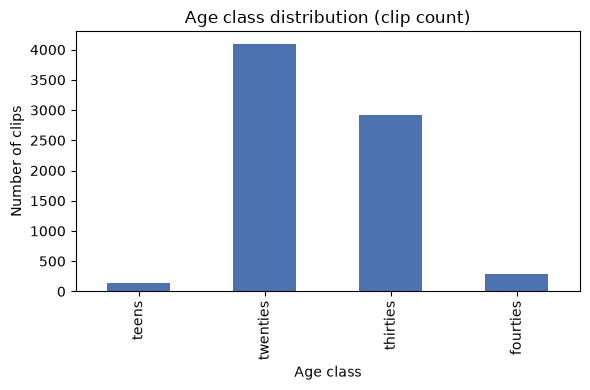

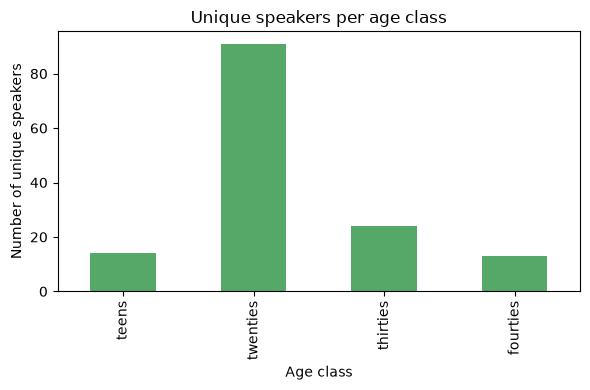


Speakers per class:
 age
teens       14
twenties    91
thirties    24
fourties    13
Name: client_id, dtype: int64


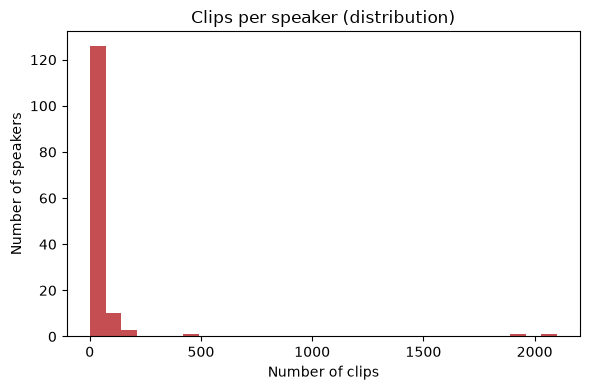

Sampling durations: 100%|██████████| 500/500 [00:11<00:00, 43.64it/s] 



6. Duration stats over a random sample of 500 clips (seconds):
   mean=4.41  median=4.19  min=1.32  max=8.90


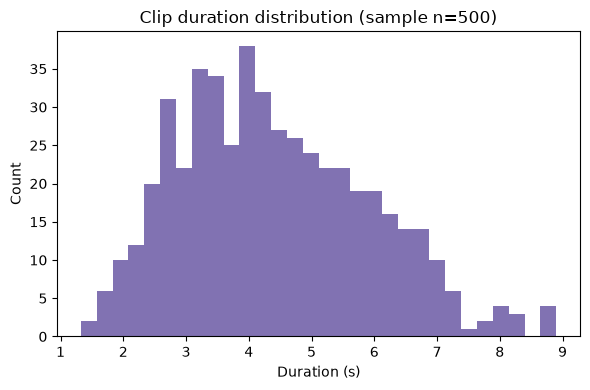


Class imbalance note: the required classes are naturally imbalanced in Common Voice Hindi.
Macro F1 is therefore treated as the primary metric (Sections 17-24), and class weighting is
used in every ML model and in the CNN loss.



In [8]:
# ============================================================
# 9. EDA
# ============================================================
print("1. Total records in base pool (validated.tsv):", n_before)
print("2. Valid/usable records after filtering:", n_after)
print("3. Unique speakers (client_id):", df["client_id"].nunique())
print("4. Age distribution:")
print(df["age"].value_counts().reindex(AGE_CLASSES))

clips_per_speaker = df.groupby("client_id").size()
print("\n5. Clips per speaker -> min/median/mean/max:",
      clips_per_speaker.min(), clips_per_speaker.median(), round(clips_per_speaker.mean(), 2), clips_per_speaker.max())

fig, ax = plt.subplots(figsize=(6, 4))
df["age"].value_counts().reindex(AGE_CLASSES).plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_title("Age class distribution (clip count)")
ax.set_xlabel("Age class"); ax.set_ylabel("Number of clips")
plt.tight_layout(); plt.show()

speakers_per_class = df.groupby("age")["client_id"].nunique().reindex(AGE_CLASSES)
fig, ax = plt.subplots(figsize=(6, 4))
speakers_per_class.plot(kind="bar", ax=ax, color="#55A868")
ax.set_title("Unique speakers per age class")
ax.set_xlabel("Age class"); ax.set_ylabel("Number of unique speakers")
plt.tight_layout(); plt.show()
print("\nSpeakers per class:\n", speakers_per_class)

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(clips_per_speaker.values, bins=30, color="#C44E52")
ax.set_title("Clips per speaker (distribution)")
ax.set_xlabel("Number of clips"); ax.set_ylabel("Number of speakers")
plt.tight_layout(); plt.show()

if HAVE_LIBROSA:
    sample_n = min(500, len(df))
    sample_paths = df["abs_path"].sample(sample_n, random_state=GLOBAL_SEED).tolist()
    durations = []
    for p in tqdm(sample_paths, desc="Sampling durations"):
        try:
            durations.append(librosa.get_duration(path=p))
        except Exception:
            pass
    durations = np.array(durations)
    print(f"\n6. Duration stats over a random sample of {len(durations)} clips (seconds):")
    print(f"   mean={durations.mean():.2f}  median={np.median(durations):.2f}  "
          f"min={durations.min():.2f}  max={durations.max():.2f}")
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(durations, bins=30, color="#8172B2")
    ax.set_title(f"Clip duration distribution (sample n={len(durations)})")
    ax.set_xlabel("Duration (s)"); ax.set_ylabel("Count")
    plt.tight_layout(); plt.show()
else:
    print("librosa not available -> skipping duration stats.")

print("""
Class imbalance note: the required classes are naturally imbalanced in Common Voice Hindi.
Macro F1 is therefore treated as the primary metric (Sections 17-24), and class weighting is
used in every ML model and in the CNN loss.
""")


## 10. Speaker-independent stratified grouped split

**Non-negotiable requirement**: the same `client_id` must never appear in more than one of train / validation / test.

We use `sklearn.model_selection.StratifiedGroupKFold(n_splits=7)`. Per the official scikit-learn documentation (verified in Section 2.3), each group (`client_id`) appears in exactly one fold's held-out portion across all folds, and within that hard non-overlap constraint the folds are made as class-balanced as possible.

Concretely:
1. Run `StratifiedGroupKFold` with `n_splits=7` → this produces a fixed fold assignment for every speaker (since a group never splits across folds, "which fold's held-out set a speaker lands in" is a well-defined, one-to-one speaker→fold mapping).
2. Compute each fold's class-distribution distance to the overall dataset's class distribution.
3. Deterministically choose the fold with the smallest distance (and all 4 classes present) as **test**, the next-smallest remaining eligible fold as **validation**, and pool the other 5 folds as **train** (~5/7 ≈ 71%, ~1/7 ≈ 14.3% each for val/test — close to the requested 70/15/15).


In [ ]:
# ============================================================
#  SPEAKER-INDEPENDENT STRATIFIED GROUPED SPLIT
# ============================================================
age_encoder_full = LabelEncoder().fit(AGE_CLASSES)
y_all = age_encoder_full.transform(df["age"].values)
groups_all = df["client_id"].values

sgkf = StratifiedGroupKFold(n_splits=N_SPLIT_FOLDS, shuffle=True, random_state=SPLIT_SEED)

# Each sample gets a fold_id = index of the fold in which it appears in the HELD-OUT portion.
# Because StratifiedGroupKFold guarantees non-overlapping groups across folds' held-out sets,
# this defines a fixed, one-to-one speaker -> fold_id mapping.
fold_id = np.full(len(df), -1, dtype=int)
for i, (_, holdout_idx) in enumerate(sgkf.split(df, y_all, groups_all)):
    fold_id[holdout_idx] = i
assert (fold_id >= 0).all(), "Every sample must be assigned to exactly one fold."
df["_fold_id"] = fold_id

# Sanity: a speaker must map to exactly one fold (guaranteed by StratifiedGroupKFold, verified anyway)
speaker_fold_counts = df.groupby("client_id")["_fold_id"].nunique()
assert (speaker_fold_counts == 1).all(), "A speaker was assigned to more than one fold -- this should be impossible."

overall_dist = df["age"].value_counts(normalize=True).reindex(AGE_CLASSES).values

fold_stats = []
for i in range(N_SPLIT_FOLDS):
    fold_df = df[df["_fold_id"] == i]
    counts = fold_df["age"].value_counts().reindex(AGE_CLASSES).fillna(0)
    props = (counts / counts.sum()).values
    all_classes_present = (counts > 0).all()
    l1_dist = np.abs(props - overall_dist).sum()
    fold_stats.append({"fold": i, "n_clips": len(fold_df), "n_speakers": fold_df["client_id"].nunique(),
                        "all_classes_present": bool(all_classes_present), "l1_dist_to_overall": l1_dist})

fold_stats_df = pd.DataFrame(fold_stats).sort_values("l1_dist_to_overall")
print("Per-fold stats (sorted by closeness to overall class distribution):")
print(fold_stats_df.to_string(index=False))

eligible = fold_stats_df[fold_stats_df["all_classes_present"]]
assert len(eligible) >= 2, "Fewer than 2 folds contain all 4 classes -- cannot pick val/test folds."

test_fold = int(eligible.iloc[0]["fold"])
val_fold = int(eligible[eligible["fold"] != test_fold].iloc[0]["fold"])
train_folds = [i for i in range(N_SPLIT_FOLDS) if i not in (test_fold, val_fold)]

print(f"\nDeterministically chosen -> test fold: {test_fold} | val fold: {val_fold} | train folds: {train_folds}")

train_split = df[df["_fold_id"].isin(train_folds)].drop(columns=["_fold_id"]).reset_index(drop=True)
val_split   = df[df["_fold_id"] == val_fold].drop(columns=["_fold_id"]).reset_index(drop=True)
test_split  = df[df["_fold_id"] == test_fold].drop(columns=["_fold_id"]).reset_index(drop=True)

train_speakers = set(train_split["client_id"])
val_speakers   = set(val_split["client_id"])
test_speakers  = set(test_split["client_id"])

print("\nUnique speakers -> train:", len(train_speakers), " val:", len(val_speakers), " test:", len(test_speakers))
print("Clips           -> train:", len(train_split),   " val:", len(val_split),   " test:", len(test_split))

print("\nAge distribution (train):\n", train_split["age"].value_counts().reindex(AGE_CLASSES))
print("\nAge distribution (val):\n",   val_split["age"].value_counts().reindex(AGE_CLASSES))
print("\nAge distribution (test):\n",  test_split["age"].value_counts().reindex(AGE_CLASSES))

for split_name, split_df in [("train", train_split), ("val", val_split), ("test", test_split)]:
    missing = set(AGE_CLASSES) - set(split_df["age"].unique())
    assert not missing, f"{split_name} split is missing age class(es): {sorted(missing)}"

train_split.to_csv(SPLITS_DIR / "train_split.csv", index=False)
val_split.to_csv(SPLITS_DIR / "val_split.csv", index=False)
test_split.to_csv(SPLITS_DIR / "test_split.csv", index=False)
print(f"\nSaved split files (method={SPLIT_VERSION}) to", SPLITS_DIR.resolve())


Per-fold stats (sorted by closeness to overall class distribution):
 fold  n_clips  n_speakers  all_classes_present  l1_dist_to_overall
    6      601          48                 True            0.297898
    4      524          18                 True            0.345879
    2      747          14                 True            0.353075
    3      525          17                 True            0.373382
    5      603          21                 True            0.419034
    0     2217          11                 True            0.789860
    1     2209          13                 True            0.942668

Deterministically chosen -> test fold: 6 | val fold: 4 | train folds: [0, 1, 2, 3, 5]

Unique speakers -> train: 76  val: 18  test: 48
Clips           -> train: 6301  val: 524  test: 601

Age distribution (train):
 age
teens         78
twenties    3348
thirties    2652
fourties     223
Name: count, dtype: int64

Age distribution (val):
 age
teens        44
twenties    341
thirties    

## 11. Leakage verification

Hard assertions, exactly as specified in the assignment. The notebook stops here if any of these ever fail.

In [ ]:
# ============================================================
# 11. LEAKAGE VERIFICATION
# ============================================================
print("train ∩ val  :", train_speakers & val_speakers)
print("train ∩ test :", train_speakers & test_speakers)
print("val ∩ test   :", val_speakers & test_speakers)

assert train_speakers.isdisjoint(val_speakers),  "LEAKAGE: some speakers appear in both train and val!"
assert train_speakers.isdisjoint(test_speakers), "LEAKAGE: some speakers appear in both train and test!"
assert val_speakers.isdisjoint(test_speakers),   "LEAKAGE: some speakers appear in both val and test!"

# Every class must be present in every split (checked again here, defensively)
for name, split in [("train", train_split), ("val", val_split), ("test", test_split)]:
    present = set(split["age"].unique())
    missing = set(AGE_CLASSES) - present
    assert not missing, f"{name} split is missing classes: {missing}"

print("\n  Speaker-independence verified: no client_id appears in more than one split.")
print("  All 4 classes present in train, validation, and test splits.")


train ∩ val  : set()
train ∩ test : set()
val ∩ test   : set()

✅ Speaker-independence verified: no client_id appears in more than one split.
✅ All 4 classes present in train, validation, and test splits.


## 12. Audio preprocessing

A single-file, on-demand loader used by every downstream step (OpenSMILE, 180-dim features, Mel images). Nothing is bulk-loaded into RAM. Failures are logged, never crash the notebook. `MAX_DURATION_SEC` is a memory-safety cap only, not a methodological choice (Section 2.2).


In [11]:
# ============================================================
# 12. AUDIO PREPROCESSING (single-file loader, used everywhere downstream)
# ============================================================
failed_audio_records = []

def load_audio_safe(path, sr=SR, max_duration=MAX_DURATION_SEC):
    """Load one audio file -> mono float32 waveform at `sr`; duration cap is optional and off by default."""
    try:
        y, _ = librosa.load(path, sr=sr, mono=True, duration=max_duration)
        if y is None or len(y) == 0:
            raise ValueError("Empty waveform after decode")
        return y
    except Exception as e:
        failed_audio_records.append({"path": path, "error": f"{type(e).__name__}: {e}"})
        return None

def flush_failed_audio_log():
    if failed_audio_records:
        pd.DataFrame(failed_audio_records).drop_duplicates(subset=["path"]).to_csv(
            RESULTS_DIR / "failed_audio_files.csv", index=False)
    n_unique_failed = len(set(r["path"] for r in failed_audio_records))
    print(f"Failed (cumulative, unique paths): {n_unique_failed}")

print("Audio loader ready. SR =", SR, " MAX_DURATION_SEC (safety cap only) =", MAX_DURATION_SEC)


Audio loader ready. SR = 16000  MAX_DURATION_SEC (safety cap only) = None


## 13. OpenSMILE 62-feature configuration and extraction

Per Section 2.2/2.3: `opensmile.FeatureSet.GeMAPSv01b` at `opensmile.FeatureLevel.Functionals`, verified to output exactly 62 features. Each clip is first decoded to mono 16 kHz with the *same* loader used everywhere else (Section 12), then handed to OpenSMILE via `process_signal(signal, sampling_rate)` — this guarantees OpenSMILE receives the same reference-rate signal as every other feature set, rather than re-decoding the file at a possibly different internal rate.


In [12]:
# ============================================================
# 13. OPENSMILE 62-FEATURE EXTRACTION
# ============================================================
if HAVE_OPENSMILE:
    smile_62 = opensmile.Smile(
        feature_set=getattr(opensmile.FeatureSet, OPENSMILE_62_FEATURE_SET),
        feature_level=getattr(opensmile.FeatureLevel, OPENSMILE_FEATURE_LEVEL),
    )
    print("opensmile version:", opensmile.__version__)
    print("62-feature config -> FeatureSet:", OPENSMILE_62_FEATURE_SET, "| FeatureLevel:", OPENSMILE_FEATURE_LEVEL)
    print("Measured output dimensionality:", len(smile_62.feature_names))
    assert len(smile_62.feature_names) == 62, \
        f"Configured '62' feature set actually produced {len(smile_62.feature_names)} features -- " \
        f"check OPENSMILE_62_FEATURE_SET in Section 5 against your course tutorial."
    print(" Verified: 62-dim output.")

    def extract_opensmile(dataframe, smile_obj, out_path, expected_dim, label):
        if out_path.exists():
            print(f"[cache hit] Loading cached {label} features from {out_path}")
            return pd.read_csv(out_path)
        rows, fail_count = [], 0
        for _, r in tqdm(dataframe.iterrows(), total=len(dataframe), desc=f"Extracting {label}"):
            y = load_audio_safe(r["abs_path"])
            if y is None:
                fail_count += 1
                continue
            try:
                feats = smile_obj.process_signal(y, SR)
                vec = feats.iloc[0].values.astype(np.float32)
                if len(vec) != expected_dim:
                    raise ValueError(f"Expected {expected_dim} dims, got {len(vec)}")
                row = {"clip_id": r["clip_id"], "client_id": r["client_id"], "age": r["age"]}
                row.update({f"f{i}": v for i, v in enumerate(vec)})
                rows.append(row)
            except Exception as e:
                fail_count += 1
                failed_audio_records.append({"path": r["abs_path"], "error": f"{label}: {type(e).__name__}: {e}"})
        result_df = pd.DataFrame(rows)
        result_df.to_csv(out_path, index=False)
        print(f"{label}: succeeded={len(result_df)}  failed={fail_count}  -> saved to {out_path}")
        return result_df

    opensmile_62_path = FEATURES_DIR / f"opensmile_62_{OPENSMILE_62_FEATURE_SET}_{OPENSMILE_FEATURE_LEVEL}.csv"
    opensmile_62_df = extract_opensmile(df, smile_62, opensmile_62_path, 62, "OpenSMILE-62")
    assert opensmile_62_df.shape[1] - 3 == 62
    print("opensmile_62 shape:", opensmile_62_df.shape)
else:
    opensmile_62_df = None
    print("Skipped: opensmile not installed.")


opensmile version: 2.6.0
62-feature config -> FeatureSet: GeMAPSv01b | FeatureLevel: Functionals
Measured output dimensionality: 62
✅ Verified: 62-dim output.


Extracting OpenSMILE-62: 100%|██████████| 7426/7426 [11:46<00:00, 10.51it/s]


OpenSMILE-62: succeeded=7426  failed=0  -> saved to project\features\opensmile_62_GeMAPSv01b_Functionals.csv
opensmile_62 shape: (7426, 65)


## 14. OpenSMILE 88-feature configuration and extraction

`opensmile.FeatureSet.eGeMAPSv01b` at `Functionals`, verified to output exactly 88 features (Section 2.2/2.3). `eGeMAPSv02` also verified to output 88 and is a one-line swap of `OPENSMILE_88_FEATURE_SET` in Section 5 if your course tutorial specifies that variant instead.


In [13]:
# ============================================================
# 14. OPENSMILE 88-FEATURE EXTRACTION
# ============================================================
if HAVE_OPENSMILE:
    smile_88 = opensmile.Smile(
        feature_set=getattr(opensmile.FeatureSet, OPENSMILE_88_FEATURE_SET),
        feature_level=getattr(opensmile.FeatureLevel, OPENSMILE_FEATURE_LEVEL),
    )
    print("88-feature config -> FeatureSet:", OPENSMILE_88_FEATURE_SET, "| FeatureLevel:", OPENSMILE_FEATURE_LEVEL)
    print("Measured output dimensionality:", len(smile_88.feature_names))
    assert len(smile_88.feature_names) == 88, \
        f"Configured '88' feature set actually produced {len(smile_88.feature_names)} features -- " \
        f"check OPENSMILE_88_FEATURE_SET in Section 5 against your course tutorial."
    print("Verified: 88-dim output.")

    opensmile_88_path = FEATURES_DIR / f"opensmile_88_{OPENSMILE_88_FEATURE_SET}_{OPENSMILE_FEATURE_LEVEL}.csv"
    opensmile_88_df = extract_opensmile(df, smile_88, opensmile_88_path, 88, "OpenSMILE-88")
    assert opensmile_88_df.shape[1] - 3 == 88
    print("opensmile_88 shape:", opensmile_88_df.shape)
else:
    opensmile_88_df = None
    print("Skipped: opensmile not installed.")


88-feature config -> FeatureSet: eGeMAPSv01b | FeatureLevel: Functionals
Measured output dimensionality: 88
Verified: 88-dim output.


Extracting OpenSMILE-88: 100%|██████████| 7426/7426 [12:40<00:00,  9.77it/s]


OpenSMILE-88: succeeded=7426  failed=0  -> saved to project\features\opensmile_88_eGeMAPSv01b_Functionals.csv
opensmile_88 shape: (7426, 91)


## 15. 180-dimensional feature extraction (MFCC + Mel + Chroma)

40 MFCC + 128 Mel-band energies (dB) + 12 Chroma, **mean-pooled over time**, concatenated to exactly 180 dimensions (Section 2.2 item 3). Called the "180-dimensional combined feature representation" — no feature selection is performed.


In [14]:
# ============================================================
# 15. 180-DIM FEATURE EXTRACTION
# ============================================================
def extract_180_features(y):
    if len(y) < N_FFT_FEAT:
        y = np.pad(y, (0, N_FFT_FEAT - len(y)))

    mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC, n_fft=N_FFT_FEAT, hop_length=HOP_LENGTH_FEAT)
    mel  = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=N_MELS, n_fft=N_FFT_FEAT, hop_length=HOP_LENGTH_FEAT)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    chroma = librosa.feature.chroma_stft(y=y, sr=SR, n_chroma=N_CHROMA, n_fft=N_FFT_FEAT, hop_length=HOP_LENGTH_FEAT)

    mfcc_vec   = mfcc.mean(axis=1)      # (40,)  -- mean over time
    mel_vec    = mel_db.mean(axis=1)    # (128,) -- mean over time
    chroma_vec = chroma.mean(axis=1)    # (12,)  -- mean over time

    vec = np.concatenate([mfcc_vec, mel_vec, chroma_vec]).astype(np.float32)
    assert vec.shape[0] == N_MFCC + N_MELS + N_CHROMA == 180
    return vec

out_path_180 = FEATURES_DIR / f"features_180_{FEATURE_180_VERSION}.csv"
if out_path_180.exists():
    print(f"[cache hit] Loading cached 180-dim features from {out_path_180}")
    features_180_df = pd.read_csv(out_path_180)
else:
    rows, fail_count = [], 0
    for _, r in tqdm(df.iterrows(), total=len(df), desc="Extracting 180-dim features"):
        y = load_audio_safe(r["abs_path"])
        if y is None:
            fail_count += 1
            continue
        vec = extract_180_features(y)
        row = {"clip_id": r["clip_id"], "client_id": r["client_id"], "age": r["age"]}
        row.update({f"f{i}": v for i, v in enumerate(vec)})
        rows.append(row)
    features_180_df = pd.DataFrame(rows)
    features_180_df.to_csv(out_path_180, index=False)
    print(f"180-dim: succeeded={len(features_180_df)}  failed={fail_count}  -> saved to {out_path_180}")

flush_failed_audio_log()
X_check = features_180_df.drop(columns=["clip_id", "client_id", "age"])
assert X_check.shape[1] == 180, f"Expected 180 columns, got {X_check.shape[1]}"
print("\n  features_180 shape (excluding id/age columns):", X_check.shape)


Extracting 180-dim features: 100%|██████████| 7426/7426 [04:07<00:00, 29.97it/s]


180-dim: succeeded=7426  failed=0  -> saved to project\features\features_180_v2-meanpool-fullclip.csv
Failed (cumulative, unique paths): 0

  features_180 shape (excluding id/age columns): (7426, 180)


## 16. Leakage-safe ML preprocessing

Each feature table is joined to the speaker-independent split (Section 10) by `clip_id`. Two scaled views are produced per feature set:

- a **tuning view**: `StandardScaler` fit on **train only**, applied to train/val — used exclusively for hyperparameter selection (Section 17);
- a **final view**: `StandardScaler` refit on **train+validation combined**, applied to train+val/test — used only for the final model fit and the one-shot test evaluation (Section 18).

This matches the assignment's explicit requirement: *"after selecting hyperparameters, refit the final classical ML model on train+validation... refit the scaler on train+validation only... then evaluate the held-out test speakers once per model."*


In [15]:
# ============================================================
# 16. LEAKAGE-SAFE ML PREPROCESSING
# ============================================================
label_encoder = age_encoder_full  # already fit on AGE_CLASSES (Section 10)

def prepare_feature_set(feat_df, name):
    feat_cols = [c for c in feat_df.columns if c.startswith("f")]

    def subset(split_df):
        merged = split_df[["clip_id"]].merge(feat_df, on="clip_id", how="inner")
        X = merged[feat_cols].values.astype(np.float32)
        y = label_encoder.transform(merged["age"].values)
        groups = merged["client_id"].values
        return X, y, groups

    X_train, y_train, g_train = subset(train_split)
    X_val,   y_val,   g_val   = subset(val_split)
    X_test,  y_test,  g_test  = subset(test_split)

    # leakage guard, repeated at the feature-table level
    assert set(g_train).isdisjoint(set(g_val))
    assert set(g_train).isdisjoint(set(g_test))
    assert set(g_val).isdisjoint(set(g_test))

    # --- tuning view: scaler fit on TRAIN ONLY ---
    tuning_scaler = StandardScaler().fit(X_train)
    X_train_tune = tuning_scaler.transform(X_train)
    X_val_tune   = tuning_scaler.transform(X_val)

    # --- final view: scaler refit on TRAIN+VAL, used only for the final model + one-shot test eval ---
    X_trainval = np.vstack([X_train, X_val])
    y_trainval = np.concatenate([y_train, y_val])
    final_scaler = StandardScaler().fit(X_trainval)
    X_trainval_final = final_scaler.transform(X_trainval)
    X_test_final = final_scaler.transform(X_test)

    print(f"[{name}] train={X_train.shape} val={X_val.shape} test={X_test.shape} "
          f"(train+val combined for final fit: {X_trainval.shape})")

    return dict(
        X_train_tune=X_train_tune, y_train=y_train, X_val_tune=X_val_tune, y_val=y_val,
        X_trainval_final=X_trainval_final, y_trainval=y_trainval,
        X_test_final=X_test_final, y_test=y_test,
        n_features=len(feat_cols),
    )

feature_sets = {}
if opensmile_62_df is not None:
    feature_sets["OpenSMILE 62"] = prepare_feature_set(opensmile_62_df, "OpenSMILE 62")
if opensmile_88_df is not None:
    feature_sets["OpenSMILE 88"] = prepare_feature_set(opensmile_88_df, "OpenSMILE 88")
feature_sets["180 combined"] = prepare_feature_set(features_180_df, "180 combined")

print("\nPrepared feature sets:", list(feature_sets.keys()))


[OpenSMILE 62] train=(6301, 62) val=(524, 62) test=(601, 62) (train+val combined for final fit: (6825, 62))
[OpenSMILE 88] train=(6301, 88) val=(524, 88) test=(601, 88) (train+val combined for final fit: (6825, 88))
[180 combined] train=(6301, 180) val=(524, 180) test=(601, 180) (train+val combined for final fit: (6825, 180))

Prepared feature sets: ['OpenSMILE 62', 'OpenSMILE 88', '180 combined']


## 17. ML hyperparameter tuning (train → validation only)

Small, fixed grids for SVM, Random Forest, and XGBoost (or its explicitly-reported fallback). Selection criterion is validation Macro F1, since the classes are imbalanced. **The test set is not touched in this section.**


In [16]:
# ============================================================
# 17. ML HYPERPARAMETER TUNING  (train -> val only, test untouched)
# ============================================================
SVM_GRID = [{"C": c, "gamma": g, "kernel": "rbf"} for c in [1, 10] for g in ["scale", 0.01]]
RF_GRID  = [{"n_estimators": n, "max_depth": d, "min_samples_split": s}
            for n in [200, 400] for d in [None, 20] for s in [2]]
XGB_GRID = [{"n_estimators": n, "max_depth": d, "learning_rate": lr}
            for n in [200, 400] for d in [4, 6] for lr in [0.1]]

MODEL_NAMES = ["SVM", "Random Forest", "XGBoost"]

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

def class_weights_dict(y_train):
    classes = np.unique(y_train)
    weights = compute_class_weight("balanced", classes=classes, y=y_train)
    return dict(zip(classes, weights))

def fit_one(model_name, params, X, y, sample_weight=None):
    if model_name == "SVM":
        clf = SVC(class_weight="balanced", random_state=GLOBAL_SEED, **params)
        clf.fit(X, y)
    elif model_name == "Random Forest":
        clf = RandomForestClassifier(class_weight="balanced", random_state=GLOBAL_SEED, n_jobs=-1, **params)
        clf.fit(X, y)
    else:  # XGBoost or fallback
        if HAVE_XGBOOST:
            clf = xgb.XGBClassifier(random_state=GLOBAL_SEED, eval_metric="mlogloss", n_jobs=-1, **params)
            clf.fit(X, y, sample_weight=sample_weight)
        else:
            clf = HistGradientBoostingClassifier(random_state=GLOBAL_SEED, max_iter=params["n_estimators"],
                                                  max_depth=params["max_depth"], learning_rate=params["learning_rate"])
            clf.fit(X, y, sample_weight=sample_weight)
    return clf

def tune_hyperparams(model_name, data):
    X_train, y_train = data["X_train_tune"], data["y_train"]
    X_val,   y_val   = data["X_val_tune"],   data["y_val"]
    cw = class_weights_dict(y_train)
    sw_train = np.array([cw[c] for c in y_train])

    grid = {"SVM": SVM_GRID, "Random Forest": RF_GRID, "XGBoost": XGB_GRID}[model_name]
    best_score, best_params = -1, None
    for params in grid:
        clf = fit_one(model_name, params, X_train, y_train, sample_weight=sw_train)
        score = macro_f1(y_val, clf.predict(X_val))
        if score > best_score:
            best_score, best_params = score, params

    fallback_note = " (HistGradientBoostingClassifier fallback)" if (model_name == "XGBoost" and not HAVE_XGBOOST) else ""
    print(f"  best {model_name}{fallback_note}: val macro-F1={best_score:.4f}  params={best_params}")
    return best_params, best_score

best_hyperparams = {}   # {(feature_set_name, model_name): (params, val_score)}
for fs_name, data in feature_sets.items():
    print(f"\n=== Tuning on feature set: {fs_name} (train -> val) ===")
    for model_name in MODEL_NAMES:
        params, val_score = tune_hyperparams(model_name, data)
        best_hyperparams[(fs_name, model_name)] = (params, val_score)



=== Tuning on feature set: OpenSMILE 62 (train -> val) ===
  best SVM: val macro-F1=0.2619  params={'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
  best Random Forest: val macro-F1=0.2204  params={'n_estimators': 400, 'max_depth': 20, 'min_samples_split': 2}
  best XGBoost: val macro-F1=0.2499  params={'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.1}

=== Tuning on feature set: OpenSMILE 88 (train -> val) ===
  best SVM: val macro-F1=0.1942  params={'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
  best Random Forest: val macro-F1=0.2176  params={'n_estimators': 400, 'max_depth': None, 'min_samples_split': 2}
  best XGBoost: val macro-F1=0.2391  params={'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.1}

=== Tuning on feature set: 180 combined (train -> val) ===
  best SVM: val macro-F1=0.2027  params={'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}
  best Random Forest: val macro-F1=0.1827  params={'n_estimators': 400, 'max_depth': 20, 'min_samples_split': 2}
  best XGBoost: val 

## 18. Final ML refit (train+validation) and held-out test evaluation

For each (feature set, model), refit using the chosen hyperparameters on **train+validation** (scaled by the train+val-fit scaler from Section 16), then evaluate **once** on the untouched test set.



--- OpenSMILE 62 + SVM (final, train+val refit, test eval) ---
              precision    recall  f1-score   support

    fourties       0.03      0.03      0.03        35
       teens       0.00      0.00      0.00        10
    thirties       0.25      0.09      0.13       147
    twenties       0.67      0.84      0.75       409

    accuracy                           0.60       601
   macro avg       0.24      0.24      0.23       601
weighted avg       0.52      0.60      0.54       601



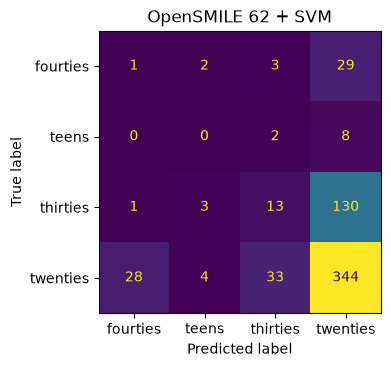


--- OpenSMILE 62 + Random Forest (final, train+val refit, test eval) ---
              precision    recall  f1-score   support

    fourties       0.00      0.00      0.00        35
       teens       0.00      0.00      0.00        10
    thirties       0.09      0.01      0.02       147
    twenties       0.68      0.95      0.79       409

    accuracy                           0.65       601
   macro avg       0.19      0.24      0.20       601
weighted avg       0.48      0.65      0.54       601



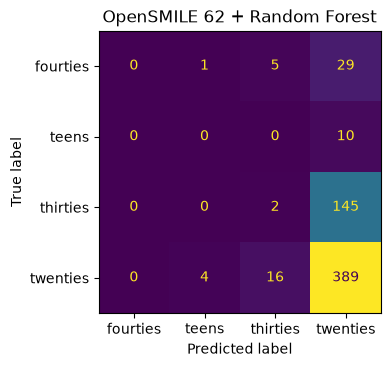


--- OpenSMILE 62 + XGBoost (final, train+val refit, test eval) ---
              precision    recall  f1-score   support

    fourties       0.08      0.03      0.04        35
       teens       0.00      0.00      0.00        10
    thirties       0.12      0.04      0.06       147
    twenties       0.65      0.83      0.73       409

    accuracy                           0.58       601
   macro avg       0.21      0.23      0.21       601
weighted avg       0.48      0.58      0.52       601



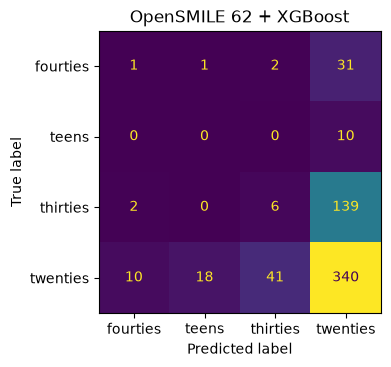


--- OpenSMILE 88 + SVM (final, train+val refit, test eval) ---
              precision    recall  f1-score   support

    fourties       0.00      0.00      0.00        35
       teens       0.00      0.00      0.00        10
    thirties       0.35      0.13      0.19       147
    twenties       0.68      0.88      0.77       409

    accuracy                           0.63       601
   macro avg       0.26      0.25      0.24       601
weighted avg       0.55      0.63      0.57       601



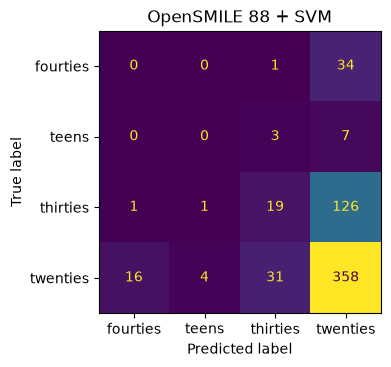


--- OpenSMILE 88 + Random Forest (final, train+val refit, test eval) ---
              precision    recall  f1-score   support

    fourties       0.00      0.00      0.00        35
       teens       0.00      0.00      0.00        10
    thirties       0.08      0.01      0.02       147
    twenties       0.68      0.96      0.79       409

    accuracy                           0.65       601
   macro avg       0.19      0.24      0.20       601
weighted avg       0.48      0.65      0.55       601



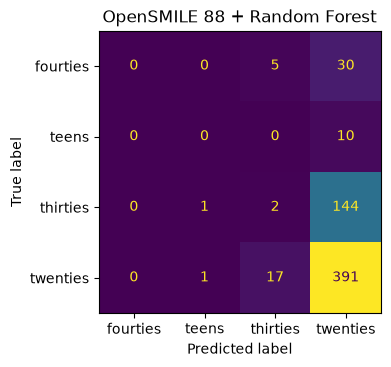


--- OpenSMILE 88 + XGBoost (final, train+val refit, test eval) ---
              precision    recall  f1-score   support

    fourties       0.06      0.03      0.04        35
       teens       0.00      0.00      0.00        10
    thirties       0.10      0.03      0.05       147
    twenties       0.67      0.84      0.75       409

    accuracy                           0.58       601
   macro avg       0.21      0.23      0.21       601
weighted avg       0.48      0.58      0.52       601



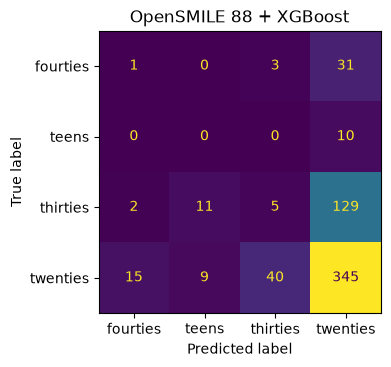


--- 180 combined + SVM (final, train+val refit, test eval) ---
              precision    recall  f1-score   support

    fourties       0.00      0.00      0.00        35
       teens       0.00      0.00      0.00        10
    thirties       0.05      0.05      0.05       147
    twenties       0.67      0.75      0.71       409

    accuracy                           0.52       601
   macro avg       0.18      0.20      0.19       601
weighted avg       0.47      0.52      0.49       601



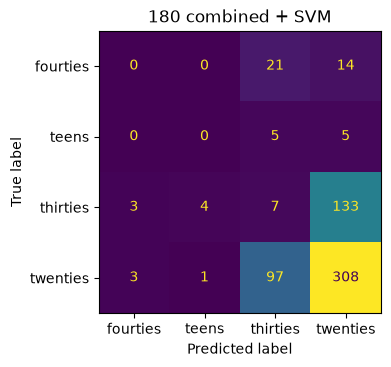


--- 180 combined + Random Forest (final, train+val refit, test eval) ---
              precision    recall  f1-score   support

    fourties       0.00      0.00      0.00        35
       teens       0.00      0.00      0.00        10
    thirties       0.06      0.04      0.05       147
    twenties       0.68      0.81      0.74       409

    accuracy                           0.56       601
   macro avg       0.18      0.21      0.20       601
weighted avg       0.48      0.56      0.51       601



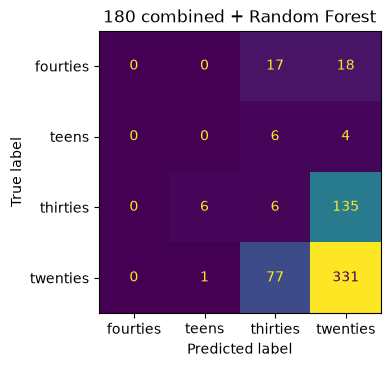


--- 180 combined + XGBoost (final, train+val refit, test eval) ---
              precision    recall  f1-score   support

    fourties       0.00      0.00      0.00        35
       teens       0.00      0.00      0.00        10
    thirties       0.07      0.07      0.07       147
    twenties       0.68      0.74      0.71       409

    accuracy                           0.52       601
   macro avg       0.19      0.20      0.19       601
weighted avg       0.48      0.52      0.50       601



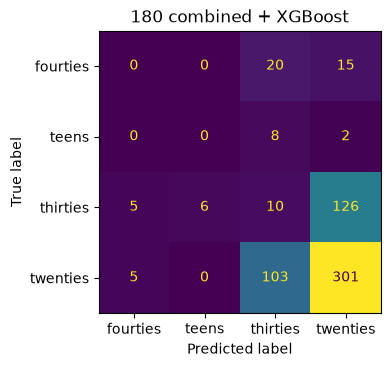


=== ML results (final, one-shot test evaluation) ===


,Feature Set,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,OpenSMILE 62,SVM,0.595674,0.240356,0.239521,0.227477,0.542830
1,OpenSMILE 62,Random Forest,0.650582,0.191460,0.241176,0.203948,0.544914
2,OpenSMILE 62,XGBoost,0.577371,0.213305,0.225171,0.208715,0.515531
3,OpenSMILE 88,SVM,0.627288,0.258439,0.251139,0.238913,0.567934
4,OpenSMILE 88,Random Forest,0.653910,0.190833,0.242399,0.204527,0.546551
5,OpenSMILE 88,XGBoost,0.584027,0.207406,0.226526,0.208943,0.522931
6,180 combined,SVM,0.524126,0.180853,0.200169,0.189851,0.494765
7,180 combined,Random Forest,0.560732,0.183721,0.212527,0.196362,0.513845
8,180 combined,XGBoost,0.517471,0.187212,0.200992,0.193797,0.497268


In [17]:
# ============================================================
# 18. FINAL ML REFIT (train+val) + ONE-SHOT TEST EVALUATION
# ============================================================
ml_results = []

for (fs_name, model_name), (params, val_score) in best_hyperparams.items():
    data = feature_sets[fs_name]
    X_trainval, y_trainval = data["X_trainval_final"], data["y_trainval"]
    X_test, y_test = data["X_test_final"], data["y_test"]

    cw = class_weights_dict(y_trainval)
    sw_trainval = np.array([cw[c] for c in y_trainval])

    final_model = fit_one(model_name, params, X_trainval, y_trainval, sample_weight=sw_trainval)
    y_pred = final_model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
    rec_macro  = recall_score(y_test, y_pred, average="macro", zero_division=0)
    f1_macro   = f1_score(y_test, y_pred, average="macro", zero_division=0)
    f1_weighted = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    print(f"\n--- {fs_name} + {model_name} (final, train+val refit, test eval) ---")
    print(classification_report(y_test, y_pred, target_names=label_encoder.classes_, zero_division=0))
    cm = confusion_matrix(y_test, y_pred, labels=range(len(AGE_CLASSES)))
    fig, ax = plt.subplots(figsize=(4, 4))
    ConfusionMatrixDisplay(cm, display_labels=label_encoder.classes_).plot(ax=ax, colorbar=False)
    ax.set_title(f"{fs_name} + {model_name}")
    plt.tight_layout(); plt.show()

    ml_results.append({
        "Feature Set": fs_name, "Model": model_name,
        "Accuracy": acc, "Macro Precision": prec_macro, "Macro Recall": rec_macro,
        "Macro F1": f1_macro, "Weighted F1": f1_weighted,
        "Best Params (tuned on val)": json.dumps(params), "Val Macro F1 (tuning stage)": val_score,
    })

ml_results_df = pd.DataFrame(ml_results)
ml_results_df.to_csv(RESULTS_DIR / "ml_results.csv", index=False)
print("\n=== ML results (final, one-shot test evaluation) ===")
ml_results_df[["Feature Set", "Model", "Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Weighted F1"]]


## 19. Mel-spectrogram image generation (for the CNN)

Clean `IMAGE_SIZE x IMAGE_SIZE` PNGs — no axes, no axis labels, no colorbar, no title — generated from the same audio files, using the **same speaker split** as the ML experiments.


In [18]:
# ============================================================
# 19. MEL-SPECTROGRAM IMAGE GENERATION  (axes/colorbar/title-free, cached)
# ============================================================
def save_mel_image(y, out_path, size=IMAGE_SIZE):
    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=N_MELS_IMG, n_fft=N_FFT_IMG, hop_length=HOP_LENGTH_IMG)
    mel_db = librosa.power_to_db(mel, ref=np.max)

    dpi = 100
    fig = plt.figure(figsize=(size / dpi, size / dpi), dpi=dpi)
    ax = fig.add_axes([0, 0, 1, 1])   # fill the whole figure, zero margins
    ax.axis("off")                     # no x-axis, no y-axis, no labels
    librosa.display.specshow(mel_db, sr=SR, hop_length=HOP_LENGTH_IMG, ax=ax, cmap="magma")
    # no colorbar call, no title call -> spectrogram image only
    fig.savefig(out_path, dpi=dpi)
    plt.close(fig)

def build_mel_image_set(split_df, split_name):
    out_dir = MEL_IMAGES_DIR / split_name
    manifest_path = out_dir / f"manifest_{MEL_IMAGE_VERSION}.csv"
    if manifest_path.exists():
        print(f"[cache hit] {split_name} mel-image manifest already exists ({manifest_path})")
        return pd.read_csv(manifest_path)

    rows = []
    for _, r in tqdm(split_df.iterrows(), total=len(split_df), desc=f"Mel images ({split_name})"):
        img_path = out_dir / f"{r['clip_id']}.png"
        if not img_path.exists():
            y = load_audio_safe(r["abs_path"])
            if y is None:
                continue
            try:
                save_mel_image(y, img_path)
            except Exception as e:
                failed_audio_records.append({"path": r["abs_path"], "error": f"mel_image: {type(e).__name__}: {e}"})
                continue
        rows.append({"clip_id": r["clip_id"], "client_id": r["client_id"], "age": r["age"], "image_path": str(img_path)})

    manifest = pd.DataFrame(rows)
    manifest.to_csv(manifest_path, index=False)
    print(f"{split_name}: {len(manifest)} images -> {out_dir}")
    return manifest

train_manifest = build_mel_image_set(train_split, "train")
val_manifest   = build_mel_image_set(val_split, "val")
test_manifest  = build_mel_image_set(test_split, "test")

flush_failed_audio_log()


Mel images (train): 100%|██████████| 6301/6301 [08:04<00:00, 13.02it/s]


train: 6301 images -> project\mel_images\train


Mel images (val): 100%|██████████| 524/524 [01:19<00:00,  6.57it/s]


val: 524 images -> project\mel_images\val


Mel images (test): 100%|██████████| 601/601 [00:59<00:00, 10.05it/s]

test: 601 images -> project\mel_images\test
Failed (cumulative, unique paths): 0


## 20. CNN dataset and normalization

Reuses the **exact same speaker split** as the ML experiments — no separate random image split. Per-channel mean/std are computed from the **training Mel images only** (not ImageNet statistics — see Section 2.1), since spectrogram images are not natural photographs.


In [19]:
# ============================================================
# 20. CNN DATASET  +  TRAIN-ONLY NORMALIZATION STATS
# ============================================================
if HAVE_TORCH:
    from PIL import Image
    import torchvision.transforms as T

    def compute_train_mean_std(manifest_df, image_size=IMAGE_SIZE, sample_n=1000, seed=GLOBAL_SEED):
        """Per-channel mean/std computed from a (possibly sampled) set of TRAINING images only."""
        rng = np.random.default_rng(seed)
        paths = manifest_df["image_path"].tolist()
        if len(paths) > sample_n:
            paths = list(rng.choice(paths, size=sample_n, replace=False))
        sum_c = np.zeros(3); sumsq_c = np.zeros(3); n_pix = 0
        for p in tqdm(paths, desc="Computing train-only mean/std"):
            img = np.array(Image.open(p).convert("RGB").resize((image_size, image_size)), dtype=np.float64) / 255.0
            sum_c += img.sum(axis=(0, 1))
            sumsq_c += (img ** 2).sum(axis=(0, 1))
            n_pix += img.shape[0] * img.shape[1]
        mean = sum_c / n_pix
        var = sumsq_c / n_pix - mean ** 2
        std = np.sqrt(np.maximum(var, 1e-8))
        return mean.tolist(), std.tolist()

    IMAGE_MEAN, IMAGE_STD = compute_train_mean_std(train_manifest)
    print("Train-image mean (per channel):", IMAGE_MEAN)
    print("Train-image std  (per channel):", IMAGE_STD)

    train_tfms = T.Compose([
        T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        T.ToTensor(),
        T.Normalize(IMAGE_MEAN, IMAGE_STD),
    ])
    eval_tfms = T.Compose([
        T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        T.ToTensor(),
        T.Normalize(IMAGE_MEAN, IMAGE_STD),
    ])

    class MelImageDataset(Dataset):
        def __init__(self, manifest_df, label_encoder, transform):
            self.df = manifest_df.reset_index(drop=True)
            self.le = label_encoder
            self.transform = transform

        def __len__(self):
            return len(self.df)

        def __getitem__(self, idx):
            row = self.df.iloc[idx]
            img = Image.open(row["image_path"]).convert("RGB")
            img = self.transform(img)
            label = int(self.le.transform([row["age"]])[0])
            return img, label

    train_ds = MelImageDataset(train_manifest, label_encoder, train_tfms)
    val_ds   = MelImageDataset(val_manifest, label_encoder, eval_tfms)
    test_ds  = MelImageDataset(test_manifest, label_encoder, eval_tfms)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                               num_workers=NUM_WORKERS, pin_memory=CUDA_AVAILABLE)
    val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=NUM_WORKERS, pin_memory=CUDA_AVAILABLE)
    test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=NUM_WORKERS, pin_memory=CUDA_AVAILABLE)

    print(f"Mel-image datasets -> train={len(train_ds)} val={len(val_ds)} test={len(test_ds)}")
else:
    print("torch not installed -> Sections 20-23 (CNN) will be skipped.")


Computing train-only mean/std: 100%|██████████| 1000/1000 [00:12<00:00, 80.92it/s]

Train-image mean (per channel): [0.37389964415449495, 0.13179095857088946, 0.3377052939144277]
Train-image std  (per channel): [0.32065568533597094, 0.1440241983414931, 0.1863351787236574]
Mel-image datasets -> train=6301 val=524 test=601


## 21. 2D CNN architecture

A compact 3-block CNN (Conv-BN-ReLU-Pool × 3) + global average pooling + dropout + FC — intentionally small, since the goal is a fair representation comparison against the ML feature sets, not a large model.

In [20]:
# ============================================================
# 21. 2D CNN ARCHITECTURE
# ============================================================
if HAVE_TORCH:
    class SimpleAgeCNN(nn.Module):
        def __init__(self, n_classes=4, dropout=0.4):
            super().__init__()
            def block(cin, cout):
                return nn.Sequential(
                    nn.Conv2d(cin, cout, kernel_size=3, padding=1),
                    nn.BatchNorm2d(cout),
                    nn.ReLU(inplace=True),
                    nn.MaxPool2d(2),
                )
            self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
            self.gap = nn.AdaptiveAvgPool2d(1)
            self.dropout = nn.Dropout(dropout)
            self.fc = nn.Linear(128, n_classes)

        def forward(self, x):
            x = self.features(x)
            x = self.gap(x).flatten(1)
            x = self.dropout(x)
            return self.fc(x)

    model_cnn = SimpleAgeCNN(n_classes=len(AGE_CLASSES)).to(DEVICE)
    n_params = sum(p.numel() for p in model_cnn.parameters())
    print(model_cnn)
    print(f"\nTotal parameters: {n_params:,}")


SimpleAgeCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (gap): AdaptiveAvgPo

## 22. CNN training

Class-weighted `CrossEntropyLoss`, Adam, `ReduceLROnPlateau`, early stopping and checkpointing **on validation Macro F1** (not loss alone, and never on test), mixed precision only when CUDA is available via the current `torch.amp` API.

Epoch 01/30 | train loss 1.0624 acc 0.6651 | val loss 1.4879 acc 0.3378 macroF1 0.1742 | *saved* | 74.5s
Epoch 02/30 | train loss 0.8858 acc 0.7275 | val loss 1.5887 acc 0.3168 macroF1 0.1692 | no improve (1) | 62.6s
Epoch 03/30 | train loss 0.7884 acc 0.7394 | val loss 2.1380 acc 0.1622 macroF1 0.1166 | no improve (2) | 81.6s
Epoch 04/30 | train loss 0.7386 acc 0.7653 | val loss 1.3225 acc 0.5248 macroF1 0.2974 | *saved* | 78.6s
Epoch 05/30 | train loss 0.7056 acc 0.7631 | val loss 1.6907 acc 0.3206 macroF1 0.1972 | no improve (1) | 82.0s
Epoch 06/30 | train loss 0.6474 acc 0.7819 | val loss 1.7300 acc 0.6298 macroF1 0.1939 | no improve (2) | 66.3s
Epoch 07/30 | train loss 0.6609 acc 0.7900 | val loss 1.3771 acc 0.5248 macroF1 0.3544 | *saved* | 64.4s
Epoch 08/30 | train loss 0.6295 acc 0.7932 | val loss 1.6223 acc 0.2023 macroF1 0.1636 | no improve (1) | 65.0s
Epoch 09/30 | train loss 0.6062 acc 0.8027 | val loss 2.4295 acc 0.2653 macroF1 0.1409 | no improve (2) | 65.1s
Epoch 10/30 |

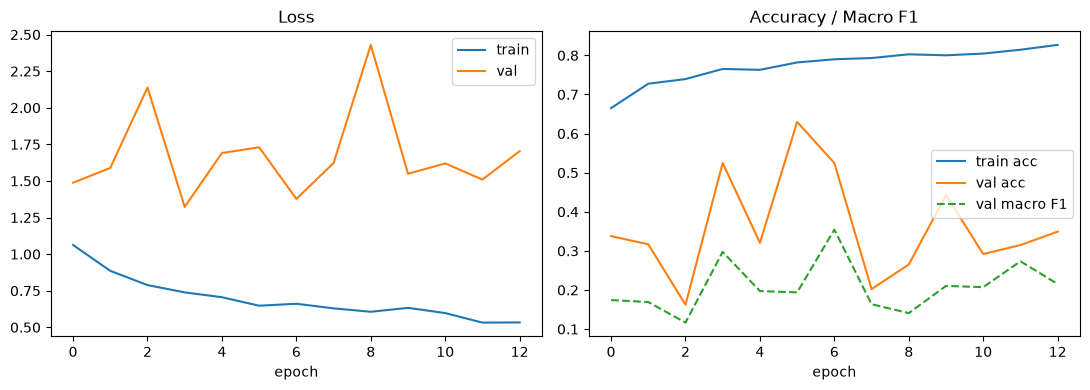

In [21]:
# ============================================================
# 22. CNN TRAINING  (best checkpoint selected by VALIDATION MACRO F1)
# ============================================================
if HAVE_TORCH:
    train_labels_np = np.array([int(label_encoder.transform([a])[0]) for a in train_manifest["age"]])
    class_weights_arr = compute_class_weight("balanced", classes=np.arange(len(AGE_CLASSES)), y=train_labels_np)
    class_weights_t = torch.tensor(class_weights_arr, dtype=torch.float32, device=DEVICE)

    criterion = nn.CrossEntropyLoss(weight=class_weights_t)
    optimizer = torch.optim.Adam(model_cnn.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)
    amp_enabled = USE_AMP and CUDA_AVAILABLE
    scaler_amp = torch.amp.GradScaler("cuda", enabled=amp_enabled)

    def run_epoch(loader, train_mode):
        model_cnn.train(train_mode)
        total_loss, all_preds, all_labels = 0.0, [], []
        for imgs, labels in loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            if train_mode:
                optimizer.zero_grad()
            with torch.set_grad_enabled(train_mode):
                with torch.amp.autocast("cuda", enabled=amp_enabled):
                    logits = model_cnn(imgs)
                    loss = criterion(logits, labels)
                if train_mode:
                    scaler_amp.scale(loss).backward()
                    scaler_amp.step(optimizer)
                    scaler_amp.update()
            total_loss += loss.item() * imgs.size(0)
            all_preds.extend(logits.argmax(1).detach().cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
        avg_loss = total_loss / len(all_labels)
        acc = accuracy_score(all_labels, all_preds)
        mf1 = f1_score(all_labels, all_preds, average="macro", zero_division=0)
        return avg_loss, acc, mf1

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_macro_f1": []}
    best_val_macro_f1 = -1.0
    epochs_no_improve = 0
    best_ckpt_path = MODELS_DIR / "best_cnn_model.pth"

    for epoch in range(1, CNN_EPOCHS + 1):
        t0 = time.time()
        tr_loss, tr_acc, _ = run_epoch(train_loader, train_mode=True)
        val_loss, val_acc, val_mf1 = run_epoch(val_loader, train_mode=False)
        scheduler.step(val_mf1)

        history["train_loss"].append(tr_loss); history["val_loss"].append(val_loss)
        history["train_acc"].append(tr_acc); history["val_acc"].append(val_acc)
        history["val_macro_f1"].append(val_mf1)

        improved = val_mf1 > best_val_macro_f1
        if improved:
            best_val_macro_f1 = val_mf1
            epochs_no_improve = 0
            torch.save({"model_state": model_cnn.state_dict(), "epoch": epoch,
                        "val_loss": val_loss, "val_acc": val_acc, "val_macro_f1": val_mf1}, best_ckpt_path)
        else:
            epochs_no_improve += 1

        print(f"Epoch {epoch:02d}/{CNN_EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} "
              f"| val loss {val_loss:.4f} acc {val_acc:.4f} macroF1 {val_mf1:.4f} "
              f"| {'*saved*' if improved else f'no improve ({epochs_no_improve})'} "
              f"| {time.time() - t0:.1f}s")

        if epochs_no_improve >= CNN_PATIENCE:
            print(f"Early stopping at epoch {epoch} (no val Macro F1 improvement for {CNN_PATIENCE} epochs).")
            break

    print(f"\nBest checkpoint (by validation Macro F1) saved to {best_ckpt_path}")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history["train_loss"], label="train"); axes[0].plot(history["val_loss"], label="val")
    axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(history["train_acc"], label="train acc"); axes[1].plot(history["val_acc"], label="val acc")
    axes[1].plot(history["val_macro_f1"], label="val macro F1", linestyle="--")
    axes[1].set_title("Accuracy / Macro F1"); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.tight_layout(); plt.show()


## 23. CNN test evaluation

Loads the checkpoint selected by validation Macro F1 and evaluates it **once** on the held-out, speaker-disjoint test set.

Loaded best checkpoint from epoch 7 (val_macro_f1=0.3544, val_loss=1.3771)
              precision    recall  f1-score   support

    fourties       0.01      0.03      0.01        35
       teens       0.00      0.00      0.00        10
    thirties       0.48      0.09      0.15       147
    twenties       0.63      0.65      0.64       409

    accuracy                           0.47       601
   macro avg       0.28      0.19      0.20       601
weighted avg       0.54      0.47      0.47       601



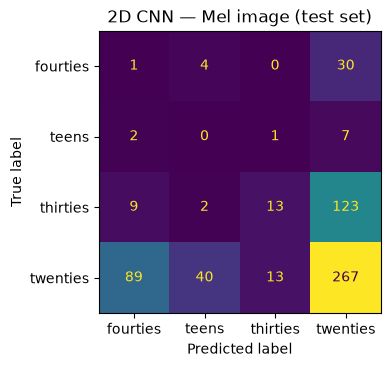

In [22]:
# ============================================================
# 23. CNN TEST EVALUATION  (best-by-val-macroF1 checkpoint, test set, once)
# ============================================================
if HAVE_TORCH:
    ckpt = torch.load(best_ckpt_path, map_location=DEVICE)
    model_cnn.load_state_dict(ckpt["model_state"])
    model_cnn.eval()
    print(f"Loaded best checkpoint from epoch {ckpt['epoch']} "
          f"(val_macro_f1={ckpt['val_macro_f1']:.4f}, val_loss={ckpt['val_loss']:.4f})")

    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = imgs.to(DEVICE)
            logits = model_cnn(imgs)
            all_preds.extend(logits.argmax(1).cpu().numpy())
            all_labels.extend(labels.numpy())

    all_preds = np.array(all_preds); all_labels = np.array(all_labels)

    cnn_acc = accuracy_score(all_labels, all_preds)
    cnn_prec = precision_score(all_labels, all_preds, average="macro", zero_division=0)
    cnn_rec  = recall_score(all_labels, all_preds, average="macro", zero_division=0)
    cnn_f1_macro = f1_score(all_labels, all_preds, average="macro", zero_division=0)
    cnn_f1_weighted = f1_score(all_labels, all_preds, average="weighted", zero_division=0)

    print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_, zero_division=0))
    cm = confusion_matrix(all_labels, all_preds, labels=range(len(AGE_CLASSES)))
    fig, ax = plt.subplots(figsize=(4, 4))
    ConfusionMatrixDisplay(cm, display_labels=label_encoder.classes_).plot(ax=ax, colorbar=False)
    ax.set_title("2D CNN — Mel image (test set)")
    plt.tight_layout(); plt.show()

    cnn_results_df = pd.DataFrame([{
        "Feature Set": "Mel image", "Model": "2D CNN",
        "Accuracy": cnn_acc, "Macro Precision": cnn_prec, "Macro Recall": cnn_rec,
        "Macro F1": cnn_f1_macro, "Weighted F1": cnn_f1_weighted,
    }])
    cnn_results_df.to_csv(RESULTS_DIR / "cnn_results.csv", index=False)
    cnn_results_df
else:
    cnn_results_df = pd.DataFrame()
    print("torch not installed -> CNN section skipped, cnn_results.csv not produced.")


## 24. Final experiment comparison — all 10 experiments

Combines the 9 ML experiments (3 feature sets × 3 models, each evaluated once on test after a train+val refit) with the CNN result. No winner is declared anywhere above this point — this table is the first place any ranking appears.

In [23]:
# ============================================================
# 24. FINAL COMPARISON TABLE
# ============================================================
final_cols = ["Feature Set", "Model", "Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Weighted F1"]
final_comparison_df = pd.concat(
    [ml_results_df[final_cols],
     cnn_results_df[final_cols] if len(cnn_results_df) else pd.DataFrame(columns=final_cols)],
    ignore_index=True
).sort_values("Macro F1", ascending=False).reset_index(drop=True)

final_comparison_df.to_csv(RESULTS_DIR / "final_comparison.csv", index=False)
print("=== FINAL COMPARISON (sorted by Macro F1) ===")
final_comparison_df


=== FINAL COMPARISON (sorted by Macro F1) ===


,Feature Set,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,OpenSMILE 88,SVM,0.627288,0.258439,0.251139,0.238913,0.567934
1,OpenSMILE 62,SVM,0.595674,0.240356,0.239521,0.227477,0.542830
2,OpenSMILE 88,XGBoost,0.584027,0.207406,0.226526,0.208943,0.522931
3,OpenSMILE 62,XGBoost,0.577371,0.213305,0.225171,0.208715,0.515531
4,OpenSMILE 88,Random Forest,0.653910,0.190833,0.242399,0.204527,0.546551
5,OpenSMILE 62,Random Forest,0.650582,0.191460,0.241176,0.203948,0.544914
6,Mel image,2D CNN,0.467554,0.279169,0.192455,0.200722,0.472099
7,180 combined,Random Forest,0.560732,0.183721,0.212527,0.196362,0.513845
8,180 combined,XGBoost,0.517471,0.187212,0.200992,0.193797,0.497268
9,180 combined,SVM,0.524126,0.180853,0.200169,0.189851,0.494765


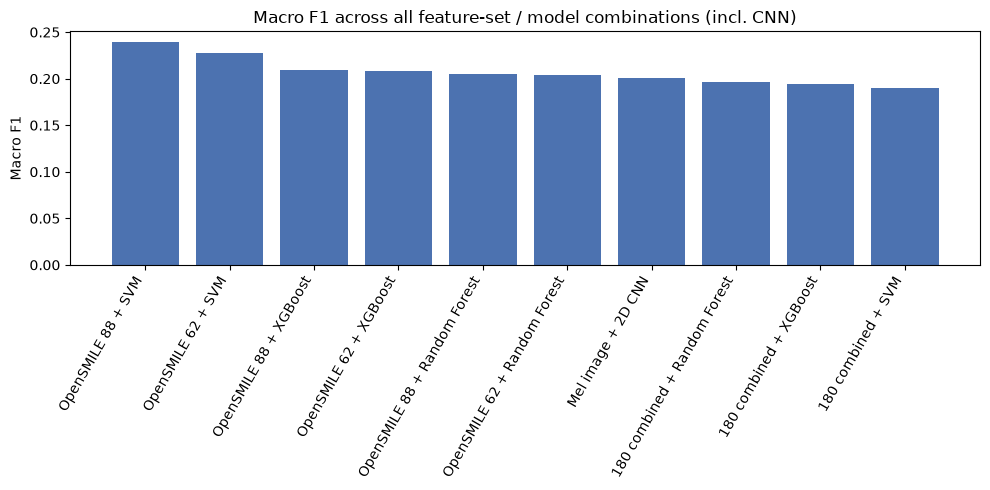

In [24]:
# --- Visual comparison ---
fig, ax = plt.subplots(figsize=(10, 5))
labels = final_comparison_df["Feature Set"] + " + " + final_comparison_df["Model"]
ax.bar(labels, final_comparison_df["Macro F1"], color="#4C72B0")
ax.set_xticklabels(labels, rotation=60, ha="right")
ax.set_ylabel("Macro F1")
ax.set_title("Macro F1 across all feature-set / model combinations (incl. CNN)")
plt.tight_layout(); plt.show()


## 25. Interpretation guidance

*(Fill in after running — deliberately not pre-written, per the assignment's explicit instruction not to declare a winner in advance.)*

Questions the `final_comparison_df` table (Section 24) actually answers, once populated:

- **Did the CNN reach the highest Macro F1**, or did one of the classical feature-based pipelines win? Compare the `Mel image + 2D CNN` row directly against the best of the 9 feature/model rows.
- **OpenSMILE 62 vs. 88 vs. 180-dim**: did the extra descriptors in eGeMAPS (62→88), or the higher-dimensional MFCC+Mel+Chroma representation, actually help — or did they overfit given the amount of training data per speaker?
- **Accuracy vs. Macro F1 divergence**: given the class imbalance documented in Section 9, check whether any model has high accuracy but low Macro F1 — a sign it is defaulting to the majority class(es).
- **Caveats**: this is a single train/val/test split (not repeated k-fold-by-speaker), so treat any close ranking between two rows as not statistically distinguishable without further validation.


## 26. Reproducibility / artifact summary

In [25]:
# ============================================================
# 26. REPRODUCIBILITY / ARTIFACT SUMMARY
# ============================================================
print("="*70)
print("FINAL REPORT")
print("="*70)
print("\nDataset:")
print(f"  Number of speakers: {df['client_id'].nunique()}")
print(f"  Number of clips: {len(df)}")
print(f"  Number of classes: {len(AGE_CLASSES)}  {AGE_CLASSES}")

print("\nSpeaker-independent split (method:", SPLIT_VERSION, "):")
print(f"  Train speakers: {len(train_speakers)}  ({len(train_split)} clips)")
print(f"  Validation speakers: {len(val_speakers)}  ({len(val_split)} clips)")
print(f"  Test speakers: {len(test_speakers)}  ({len(test_split)} clips)")

print("\nBest measured ML results (by Macro F1):")
print(ml_results_df.sort_values("Macro F1", ascending=False)[final_cols].to_string(index=False))

if len(cnn_results_df):
    print("\n2D CNN results:")
    print(cnn_results_df[final_cols].to_string(index=False))

print("\nFinal comparison (all experiments, sorted by Macro F1):")
print(final_comparison_df.to_string(index=False))

print("\nKey artifacts:")
print("  Splits:  ", SPLITS_DIR.resolve())
print("  Features:", FEATURES_DIR.resolve())
print("  Images:  ", MEL_IMAGES_DIR.resolve())
print("  Models:  ", MODELS_DIR.resolve())
print("  Results: ", RESULTS_DIR.resolve())
print("\nMethodological guarantees enforced in this run:")
print("  - Speaker-independent split via StratifiedGroupKFold (Section 10-11)")
print("  - Speakers with inconsistent age labels excluded (Section 8)")
print("  - Scalers/tuning fit on train (or train+val for the final fit) only, never on test (Sections 16-18)")
print("  - Hyperparameters chosen on validation Macro F1 only; test touched once per model (Sections 17-18)")
print("  - CNN checkpoint chosen by validation Macro F1, evaluated once on test (Sections 22-23)")
print("  - CNN image normalization computed from training images only, not ImageNet (Section 20)")
print("  - Audio duration cap:", "OFF (full clip)" if MAX_DURATION_SEC is None else MAX_DURATION_SEC)


FINAL REPORT

Dataset:
  Number of speakers: 142
  Number of clips: 7426
  Number of classes: 4  ['teens', 'twenties', 'thirties', 'fourties']

Speaker-independent split (method: v2-stratifiedgroupkfold7 ):
  Train speakers: 76  (6301 clips)
  Validation speakers: 18  (524 clips)
  Test speakers: 48  (601 clips)

Best measured ML results (by Macro F1):
 Feature Set         Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1
OpenSMILE 88           SVM  0.627288         0.258439      0.251139  0.238913     0.567934
OpenSMILE 62           SVM  0.595674         0.240356      0.239521  0.227477     0.542830
OpenSMILE 88       XGBoost  0.584027         0.207406      0.226526  0.208943     0.522931
OpenSMILE 62       XGBoost  0.577371         0.213305      0.225171  0.208715     0.515531
OpenSMILE 88 Random Forest  0.653910         0.190833      0.242399  0.204527     0.546551
OpenSMILE 62 Random Forest  0.650582         0.191460      0.241176  0.203948     0.544914
180 comb